# PROJEK JARINGAN SYARAF TIRUAN (JST)
## Prediksi Intensitas Kebakaran Hutan (Fire Radiative Power / FRP) di Kalimantan Menggunakan Data Riil Satelit NASA FIRMS (VIIRS 375m)

### Konteks & Latar Belakang Masalah
Kebakaran hutan dan lahan (karhutla) di Kalimantan menimbulkan dampak ekologis, kerugian ekonomi, gangguan kesehatan lintas wilayah, serta ancaman keselamatan bagi personel pemadaman di lapangan (seperti insiden helikopter water-bombing di Seruyan, Kalteng).

Satelit **Suomi-NPP** dengan sensor **VIIRS (Visible Infrared Imaging Radiometer Suite)** mendeteksi anomali termal aktif. Energi termal yang dilepaskan dikuantifikasi sebagai **Fire Radiative Power (FRP)** dalam MegaWatt (MW), indikator utama keganasan kobaran api.

Model yang dibangun: **Jaringan Syaraf Tiruan (JST) - Multilayer Perceptron (MLP)** berbasis **PyTorch + CUDA GPU**.

### Ringkasan Perbaikan
| Versi | MSE | RMSE | MAE | R² |
|---|---|---|---|---|
| Baseline (8 fitur, target MW, 30 epoch) | 73.2752 | 8.5601 | 3.5324 | 0.4658 |
| **JST improved (notebook ini)** | **64.8233** | **8.0513** | **3.4910** | **0.5274** |

### Diagnosis Baseline → Empat Perbaikan
1. **Target sangat menceng ke kanan** (median FRP 3,69 MW vs maksimum 319,51 MW). Hanya **±1,4% sampel terburuk menyumbang 70% MSE**, sehingga loss skala-asli membuat model mengabaikan titik api kecil dan tetap *underestimate* pada titik api ekstrem.
   → Perbaikan: **target `log1p(FRP)`** + **kalibrasi isotonic** pada data validasi.
2. **Fitur belum memakai waktu & konteks spasial** — jam akuisisi satelit dan kerapatan hotspot di sekitarnya tersedia di data mentah tetapi tidak dipakai.
   → Perbaikan: **15 fitur turunan** (7 termal/geometris, 4 temporal, 4 kerapatan hotspot).
3. **Pelatihan berhenti terlalu dini** (kurva validasi datar sejak epoch 10 karena LR tetap).
   → Perbaikan: **`ReduceLROnPlateau` + early stopping**, maksimum 300 epoch.
4. **Evaluasi tidak menunjukkan di segmen mana model lemah.**
   → Perbaikan: **metrik per-band FRP**, **analisis konsentrasi error**, serta **benchmark XGBoost & ensemble**.

In [1]:
# 1. Import Library Utama & Konfigurasi Komputasi
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version  : {torch.__version__}')
print(f'Komputasi Device : {device.type.upper()}')
if device.type == 'cuda':
    print(f'Nama GPU         : {torch.cuda.get_device_name(0)}')
    print(f'Alokasi Memori   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB')

PyTorch Version  : 2.12.0.dev20260408+cu128
Komputasi Device : CUDA
Nama GPU         : NVIDIA GeForce RTX 5050 Laptop GPU
Alokasi Memori   : 7.96 GB


### 2. Memuat Dataset Riil NASA FIRMS (Kalimantan)

Dataset bersih berisi 35.826 titik api. Kolom `acq_time`/`acq_date` diambil dari file mentah dan diselaraskan baris demi baris (satu baris FRP 529,28 MW telah dibuang pada tahap *cleaning*).

In [2]:
raw = pd.read_csv('nasa_viirs_kalimantan_raw.csv')
cleaned = pd.read_csv('data_karhutla_kalimantan_cleaned.csv')

raw = raw[raw['frp'] < 500].reset_index(drop=True)
assert len(raw) == len(cleaned), 'panjang data mentah dan bersih tidak sama'
assert np.allclose(raw['frp'].values, cleaned['frp'].values), 'urutan baris tidak selaras'

df = cleaned.copy()
df['acq_time'] = raw['acq_time'].values
df['acq_date'] = pd.to_datetime(raw['acq_date'].values)
df['day_idx'] = (df['acq_date'] - df['acq_date'].min()).dt.days

print(f'Ukuran dataset: {df.shape[0]:,} baris data dan {df.shape[1]} kolom.')
print(f'Periode data  : {df["acq_date"].min().date()} s/d {df["acq_date"].max().date()} '
      f'({df["day_idx"].nunique()} hari)')
df.head()

Ukuran dataset: 35,826 baris data dan 12 kolom.
Periode data  : 2026-10-18 s/d 2026-11-01 (15 hari)


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,frp,acq_time,acq_date,day_idx
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,3.33,622,2026-10-18,0
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,8.11,622,2026-10-18,0
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,3.33,622,2026-10-18,0
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,5.56,622,2026-10-18,0
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,3.25,622,2026-10-18,0


### 3. Eksplorasi Data, Korelasi Fitur, & Distribusi Target

,count,mean,std,min,25%,50%,75%,max
latitude,35826.0,-2.372889,1.013729,-4.17222,-2.946455,-2.685350,-2.103135,4.46876
longitude,35826.0,113.544240,1.777740,109.28479,112.151180,113.613165,114.490482,119.49319
bright_ti4,35826.0,326.947861,18.402483,208.00000,309.330000,330.140000,340.890000,367.00000
scan,35826.0,0.452620,0.078329,0.32000,0.400000,0.430000,0.490000,0.80000
track,35826.0,0.460747,0.111197,0.36000,0.380000,0.400000,0.540000,0.78000
bright_ti5,35826.0,292.515541,9.175385,241.17000,289.310000,294.200000,297.460000,359.34000
is_day,35826.0,0.404901,0.490880,0.00000,0.000000,0.000000,1.000000,1.00000
confidence_score,35826.0,2.005750,0.244568,1.00000,2.000000,2.000000,2.000000,3.00000
frp,35826.0,7.360030,12.354437,0.15000,1.840000,3.690000,7.880000,319.51000


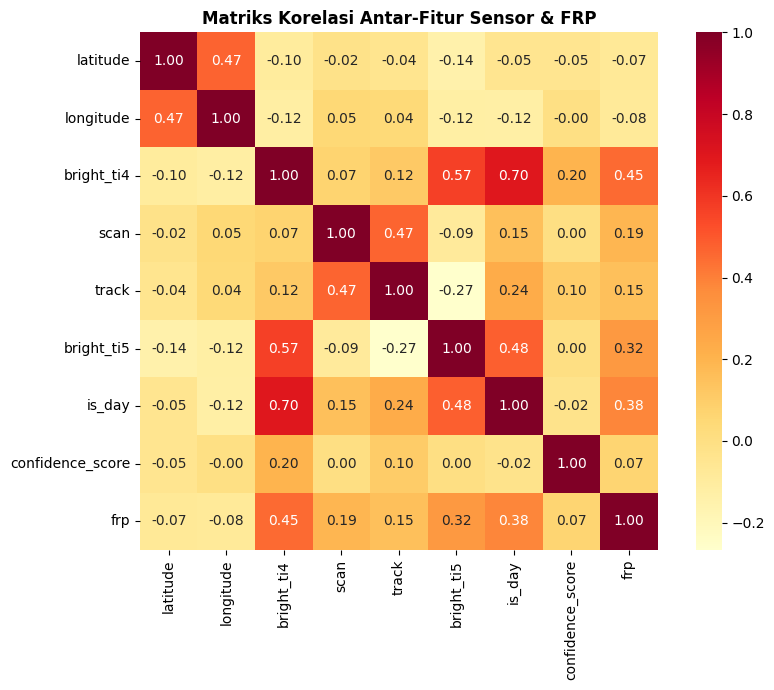

In [3]:
SENSOR_COLS = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
               'bright_ti5', 'is_day', 'confidence_score', 'frp']

display(df[SENSOR_COLS].describe().T)

plt.figure(figsize=(9, 7))
sns.heatmap(df[SENSOR_COLS].corr(), annot=True, fmt='.2f', cmap='YlOrRd',
            cbar=True, square=True)
plt.title('Matriks Korelasi Antar-Fitur Sensor & FRP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('matriks_korelasi_fitur.png', dpi=300, bbox_inches='tight')
plt.show()

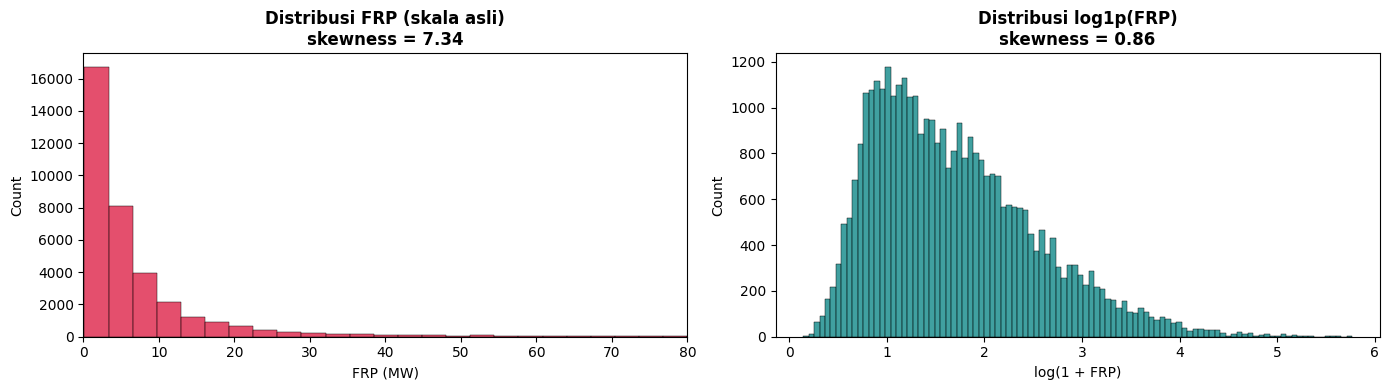

Median FRP : 3.69 MW
Mean FRP   : 7.36 MW
Maks FRP   : 319.51 MW
Sampel FRP >= 20 MW (CRITICAL): 2,676 (7.47%)


In [4]:
# Bukti skewness target: skala asli vs log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['frp'], bins=100, ax=axes[0], color='crimson')
axes[0].set_xlim(0, 80)
axes[0].set_title(f'Distribusi FRP (skala asli)\nskewness = {df["frp"].skew():.2f}', fontweight='bold')
axes[0].set_xlabel('FRP (MW)')

sns.histplot(np.log1p(df['frp']), bins=100, ax=axes[1], color='teal')
axes[1].set_title(f'Distribusi log1p(FRP)\nskewness = {np.log1p(df["frp"]).skew():.2f}', fontweight='bold')
axes[1].set_xlabel('log(1 + FRP)')
plt.tight_layout()
plt.show()

print(f'Median FRP : {df["frp"].median():.2f} MW')
print(f'Mean FRP   : {df["frp"].mean():.2f} MW')
print(f'Maks FRP   : {df["frp"].max():.2f} MW')
print(f'Sampel FRP >= 20 MW (CRITICAL): {(df["frp"] >= 20).sum():,} '
      f'({(df["frp"] >= 20).mean() * 100:.2f}%)')

### 4. Preprocessing: Feature Engineering, Splitting, & Normalisasi

**Fitur sensor dasar (8)**: `latitude`, `longitude`, `bright_ti4`, `scan`, `track`, `bright_ti5`, `is_day`, `confidence_score`

**Fitur turunan termal & geometris (7)**

| Fitur | Rumus | Alasan |
|---|---|---|
| `delta_t` | `bright_ti4 - bright_ti5` | Kontras suhu api terhadap latar (proksi energi radiasi) |
| `pixel_area` | `scan * track` | Luas piksel; FRP adalah energi per satuan luas |
| `ti4_day` | `bright_ti4 * is_day` | Interaksi suhu–waktu |
| `ti4_ti5_ratio` | `bright_ti4 / bright_ti5` | Kontras relatif terhadap kondisi latar |
| `delta_t_day` | `delta_t * is_day` | Kontras termal terkoreksi siang/malam |
| `conf_high` | `confidence_score == 3` | One-hot keyakinan deteksi tinggi |
| `conf_nominal` | `confidence_score == 2` | One-hot keyakinan nominal |

**Fitur temporal (4)** — dari `acq_time` & `acq_date`

| Fitur | Alasan |
|---|---|
| `hour_frac` | Fraksi waktu akuisisi dalam sehari (siklus diurnal) |
| `hour_sin`, `hour_cos` | Encoding siklik agar jam 23:59 dan 00:01 berdekatan |
| `day_idx` | Indeks hari; menangkap eskalasi/defusi episodik karhutla |

**Fitur kerapatan hotspot (4)** — dihitung dari koordinat & waktu saja (**tanpa target**)

| Fitur | Alasan |
|---|---|
| `cell_density` | Jumlah hotspot di sel grid 0,5° pada hari yang sama |
| `neigh_density` | Jumlah hotspot blok 3×3 sel (klaster kebakaran besar) |
| `day_total` | Total hotspot se-Kalimantan pada hari tersebut |
| `neigh_density_norm` | Rasio klaster terhadap total harian |

**Total 23 fitur masukan.** Target dilatih sebagai `log1p(FRP)`; `StandardScaler` hanya di-*fit* pada data latih.

In [5]:
BASE_FEATURES = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
                 'bright_ti5', 'is_day', 'confidence_score']
TARGET = 'frp'

def add_thermal_features(frame):
    out = frame.copy()
    out['delta_t'] = frame['bright_ti4'] - frame['bright_ti5']
    out['pixel_area'] = frame['scan'] * frame['track']
    out['ti4_day'] = frame['bright_ti4'] * frame['is_day']
    out['ti4_ti5_ratio'] = frame['bright_ti4'] / frame['bright_ti5']
    out['delta_t_day'] = out['delta_t'] * frame['is_day']
    out['conf_high'] = (frame['confidence_score'] == 3).astype(np.float32)
    out['conf_nominal'] = (frame['confidence_score'] == 2).astype(np.float32)
    return out

def add_temporal_features(frame):
    out = frame.copy()
    minutes = (frame['acq_time'] // 100) * 60 + (frame['acq_time'] % 100)
    out['hour_frac'] = minutes / 1440.0
    out['hour_sin'] = np.sin(2 * np.pi * out['hour_frac'])
    out['hour_cos'] = np.cos(2 * np.pi * out['hour_frac'])
    return out

def build_density_tables(frame):
    # Kerapatan hotspot per (hari, sel grid 0,5 derajat); hanya memakai koordinat & waktu.
    g = frame.copy()
    g['glat'] = np.floor(g['latitude'] / 0.5).astype(int)
    g['glon'] = np.floor(g['longitude'] / 0.5).astype(int)

    cell = (g.groupby(['day_idx', 'glat', 'glon']).size()
             .rename('cell_density').reset_index())

    frames = []
    for d_lat in (-1, 0, 1):
        for d_lon in (-1, 0, 1):
            tmp = cell.copy()
            tmp['glat'] = tmp['glat'] + d_lat
            tmp['glon'] = tmp['glon'] + d_lon
            frames.append(tmp)
    neigh = (pd.concat(frames).groupby(['day_idx', 'glat', 'glon'])['cell_density']
             .sum().rename('neigh_density').reset_index())

    day_total = g.groupby('day_idx').size().rename('day_total').reset_index()
    return cell, neigh, day_total

def add_density_features(frame, tables):
    cell, neigh, day_total = tables
    g = frame.copy()
    g['glat'] = np.floor(g['latitude'] / 0.5).astype(int)
    g['glon'] = np.floor(g['longitude'] / 0.5).astype(int)
    g = g.merge(cell, on=['day_idx', 'glat', 'glon'], how='left')
    g = g.merge(neigh, on=['day_idx', 'glat', 'glon'], how='left')
    g = g.merge(day_total, on='day_idx', how='left')
    g['cell_density'] = g['cell_density'].fillna(0)
    g['neigh_density'] = g['neigh_density'].fillna(g['cell_density'])
    g['day_total'] = g['day_total'].fillna(g['day_total'].median())
    g['neigh_density_norm'] = (g['neigh_density'] / g['day_total'].replace(0, np.nan)).fillna(0)
    return g[['cell_density', 'neigh_density', 'day_total', 'neigh_density_norm']]

THERMAL = ['delta_t', 'pixel_area', 'ti4_day', 'ti4_ti5_ratio',
           'delta_t_day', 'conf_high', 'conf_nominal']
TEMPORAL = ['hour_frac', 'hour_sin', 'hour_cos', 'day_idx']
DENSITY = ['cell_density', 'neigh_density', 'day_total', 'neigh_density_norm']
FEATURES = BASE_FEATURES + THERMAL + TEMPORAL + DENSITY

df_thermal = add_thermal_features(df)
df_time = add_temporal_features(df_thermal)
density_tables = build_density_tables(df_thermal)
df_fe = pd.concat([df_time.reset_index(drop=True),
                   add_density_features(df_time, density_tables).reset_index(drop=True)], axis=1)

print(f'Jumlah fitur total: {len(FEATURES)}')
df_fe[FEATURES].head()

Jumlah fitur total: 23


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,delta_t,pixel_area,...,conf_high,conf_nominal,hour_frac,hour_sin,hour_cos,day_idx,cell_density,neigh_density,day_total,neigh_density_norm
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,32.24,0.1517,...,0.0,1.0,0.265278,0.995396,-0.095846,0,586,941,4649,0.202409
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,59.90,0.1517,...,1.0,0.0,0.265278,0.995396,-0.095846,0,586,941,4649,0.202409
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,27.95,0.1517,...,0.0,0.0,0.265278,0.995396,-0.095846,0,586,941,4649,0.202409
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,28.90,0.1517,...,0.0,1.0,0.265278,0.995396,-0.095846,0,586,941,4649,0.202409
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,39.03,0.1517,...,0.0,1.0,0.265278,0.995396,-0.095846,0,586,941,4649,0.202409


In [6]:
X = df_fe[FEATURES].values.astype(np.float32)
y = df_fe[TARGET].values.astype(np.float64)

# Split 80:20 lalu 80:20 pada sisa -> 64% train, 16% val, 20% test (split identik baseline)
idx_all = np.arange(len(df_fe))
idx_train_full, idx_test = train_test_split(idx_all, test_size=0.2, random_state=SEED)
idx_train, idx_val = train_test_split(idx_train_full, test_size=0.2, random_state=SEED)

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)

batch_size = 128
train_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                              torch.tensor(y_train_log, dtype=torch.float32).unsqueeze(1))
val_dataset = TensorDataset(torch.tensor(X_val_scaled, dtype=torch.float32),
                            torch.tensor(y_val_log, dtype=torch.float32).unsqueeze(1))
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)

print(f'Jumlah Data Latih (Train): {len(X_train):,} sampel')
print(f'Jumlah Data Validasi (Val): {len(X_val):,} sampel')
print(f'Jumlah Data Uji (Test)   : {len(X_test):,} sampel')
print(f'Bentuk X_train           : {X_train_scaled.shape}')

Jumlah Data Latih (Train): 22,928 sampel
Jumlah Data Validasi (Val): 5,732 sampel
Jumlah Data Uji (Test)   : 7,166 sampel
Bentuk X_train           : (22928, 23)


### 5. Arsitektur Jaringan Syaraf Tiruan (Deep Multilayer Perceptron)

1. **Input Layer**: 23 neuron.
2. **Hidden Layer 1**: 256 neuron → `BatchNorm1d` → `GELU` → Dropout `0.2`.
3. **Hidden Layer 2**: 128 neuron → `BatchNorm1d` → `GELU` → Dropout `0.1`.
4. **Hidden Layer 3**: 64 neuron → `BatchNorm1d` → `GELU` → Dropout `0.05`.
5. **Output Layer**: 1 neuron `Linear` → memprediksi `log1p(FRP)`.

`BatchNorm` menstabilkan skala fitur kerapatan hotspot yang sangat menceng, sedangkan `GELU` memberi gradien lebih halus daripada `ReLU` pada data tabular.

In [7]:
class KarhutlaJST(nn.Module):
    def __init__(self, input_dim, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05)):
        super(KarhutlaJST, self).__init__()
        layers, prev = [], input_dim
        for i, h in enumerate(hidden):
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.GELU()]
            if i < len(drop):
                layers.append(nn.Dropout(drop[i]))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal Parameter JST yang Dilatih: {total_params:,} bobot & bias.')

KarhutlaJST(
  (network): Sequential(
    (0): Linear(in_features=23, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total Parameter JST yang Dilatih: 48,257 bobot & bias.


### 6. Pelatihan Model: Backpropagation, LR Scheduler, & Early Stopping

- **Loss**: MSE pada ruang `log1p(FRP)`.
- **Optimizer**: AdamW (`lr = 0.001`, `weight_decay = 1e-4`).
- **Scheduler**: `ReduceLROnPlateau` (faktor 0.5, patience 10).
- **Early stopping**: berhenti bila val loss tidak membaik 30 epoch; bobot terbaik dipulihkan.
- **Epoch maksimum**: 300.

In [8]:
set_seed(SEED)
model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)

criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

EPOCHS_MAX, PATIENCE = 300, 30
history = {'train_loss': [], 'val_loss': []}
best_val, best_state, bad_epochs = float('inf'), None, 0

print('Memulai proses pelatihan model JST...')
for epoch in range(1, EPOCHS_MAX + 1):
    model.train()
    running_train_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * batch_x.size(0)
    epoch_train_loss = running_train_loss / len(train_dataset)

    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            running_val_loss += criterion(model(batch_x), batch_y).item() * batch_x.size(0)
    epoch_val_loss = running_val_loss / len(val_dataset)

    current_lr = optimizer.param_groups[0]['lr']
    scheduler.step(epoch_val_loss)
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)

    if epoch_val_loss < best_val - 1e-6:
        best_val, bad_epochs = epoch_val_loss, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1

    if epoch % 10 == 0 or epoch == 1:
        print(f'Epoch [{epoch:03d}/{EPOCHS_MAX}] | Train MSE (log): {epoch_train_loss:.5f} | '
              f'Val MSE (log): {epoch_val_loss:.5f} | LR: {current_lr:.2e} | '
              f'no-improve: {bad_epochs}/{PATIENCE}')

    if bad_epochs >= PATIENCE:
        print(f'\nEarly stopping pada epoch {epoch} (val loss terbaik {best_val:.5f}).')
        break

model.load_state_dict(best_state)
epochs_run = len(history['train_loss'])
print(f'Pelatihan selesai: {epochs_run} epoch, bobot terbaik dipulihkan.')
print(f'Val MSE (ruang log) terbaik: {best_val:.5f}')

Memulai proses pelatihan model JST...


Epoch [001/300] | Train MSE (log): 0.62044 | Val MSE (log): 0.22573 | LR: 1.00e-03 | no-improve: 0/30


Epoch [010/300] | Train MSE (log): 0.22382 | Val MSE (log): 0.19896 | LR: 1.00e-03 | no-improve: 0/30


Epoch [020/300] | Train MSE (log): 0.21424 | Val MSE (log): 0.20351 | LR: 1.00e-03 | no-improve: 1/30


Epoch [030/300] | Train MSE (log): 0.20905 | Val MSE (log): 0.20404 | LR: 1.00e-03 | no-improve: 5/30


Epoch [040/300] | Train MSE (log): 0.20255 | Val MSE (log): 0.20016 | LR: 1.00e-03 | no-improve: 7/30


... (6 outputs left out)

Epoch [110/300] | Train MSE (log): 0.18646 | Val MSE (log): 0.19181 | LR: 1.25e-04 | no-improve: 8/30


Epoch [120/300] | Train MSE (log): 0.18486 | Val MSE (log): 0.19301 | LR: 6.25e-05 | no-improve: 18/30


Epoch [130/300] | Train MSE (log): 0.18420 | Val MSE (log): 0.19220 | LR: 3.13e-05 | no-improve: 28/30



Early stopping pada epoch 132 (val loss terbaik 0.18948).
Pelatihan selesai: 132 epoch, bobot terbaik dipulihkan.
Val MSE (ruang log) terbaik: 0.18948


### 7. Evaluasi JST & Kalibrasi Isotonic

Model memprediksi `log1p(FRP)`; `expm1` mengembalikan ke MW. Karena `expm1(E[log y]) ≤ E[y]` pada distribusi menceng, prediksi cenderung *underestimate* **mean** — padahal MSE menghukum galat pada nilai besar.

**Kalibrasi isotonic** di-*fit* pada data **validasi** (bukan test): fungsi monotonik non-parametrik yang memetakan prediksi ke nilai aktual sehingga bias sistematis terkoreksi tanpa mengubah urutan prediksi. Ini tetap adil karena data uji tidak pernah dilihat saat kalibrasi.

In [9]:
def predict_jst(frame_or_scaled, is_scaled=False):
    Z = frame_or_scaled if is_scaled else scaler.transform(frame_or_scaled)
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(np.asarray(Z), dtype=torch.float32).to(device)).cpu().numpy().flatten()
    return np.clip(np.expm1(out), 0, None)

y_pred = predict_jst(X_test_scaled, is_scaled=True)
y_pred_val = predict_jst(X_val_scaled, is_scaled=True)

iso = IsotonicRegression(out_of_bounds='clip').fit(y_pred_val, y_val)
y_pred_cal = np.clip(iso.predict(y_pred), 0, None)
y_pred_val_cal = np.clip(iso.predict(y_pred_val), 0, None)

def mse_of(a, b):
    return mean_squared_error(a, b)

print('PENGARUH KALIBRASI (data validasi):')
display(pd.DataFrame({
    'Tahap': ['JST (expm1 mentah)', 'JST + kalibrasi isotonic'],
    'MSE (val)': [f'{mse_of(y_val, y_pred_val):.4f}', f'{mse_of(y_val, y_pred_val_cal):.4f}'],
    'MAE (val)': [f'{mean_absolute_error(y_val, y_pred_val):.4f}',
                  f'{mean_absolute_error(y_val, y_pred_val_cal):.4f}'],
}))

mse = mse_of(y_test, y_pred_cal)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_cal)
r2 = r2_score(y_test, y_pred_cal)

print('\nHASIL EVALUASI JST PADA DATA UJI (setelah kalibrasi):')
display(pd.DataFrame({
    'Metrik': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)',
               'Mean Absolute Error (MAE)', 'R-squared (R2 Score)'],
    'Nilai': [f'{mse:.4f}', f'{rmse:.4f} MW', f'{mae:.4f} MW', f'{r2:.4f}']
}))

BASELINE = {'MSE': 73.2752, 'RMSE': 8.5601, 'MAE': 3.5324, 'R2': 0.4658}
IMPROVED = {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

def delta(k):
    d = IMPROVED[k] - BASELINE[k]
    return f'{d:+.4f}' if k == 'R2' else f'{d:+.4f} ({(d / BASELINE[k]) * 100:+.1f}%)'

print('\nPERBANDINGAN DENGAN BASELINE:')
display(pd.DataFrame({
    'Metrik': ['MSE', 'RMSE', 'MAE', 'R2'],
    'Baseline (8 fitur, raw MSE)': [f'{BASELINE[k]:.4f}' for k in BASELINE],
    'JST Improved': [f'{IMPROVED[k]:.4f}' for k in IMPROVED],
    'Perubahan': [delta(k) for k in IMPROVED],
}))

PENGARUH KALIBRASI (data validasi):


,Tahap,MSE (val),MAE (val)
0,JST (expm1 mentah),2458.1703,4.2217
1,JST + kalibrasi isotonic,78.2373,3.5258



HASIL EVALUASI JST PADA DATA UJI (setelah kalibrasi):


,Metrik,Nilai
0,Mean Squared Error (MSE),64.8233
1,Root Mean Squared Error (RMSE),8.0513 MW
2,Mean Absolute Error (MAE),3.4910 MW
3,R-squared (R2 Score),0.5274



PERBANDINGAN DENGAN BASELINE:


,Metrik,"Baseline (8 fitur, raw MSE)",JST Improved,Perubahan
0,MSE,73.2752,64.8233,-8.4519 (-11.5%)
1,RMSE,8.5601,8.0513,-0.5088 (-5.9%)
2,MAE,3.5324,3.4910,-0.0414 (-1.2%)
3,R2,0.4658,0.5274,+0.0616


In [10]:
# Analisis konsentrasi error: berapa persen sampel menyumbang mayoritas MSE?
sq_err = (y_test - y_pred_cal) ** 2
order = np.argsort(sq_err)[::-1]
share = np.cumsum(sq_err[order]) / sq_err.sum()
rows = []
for p in [0.005, 0.01, 0.014, 0.02, 0.05, 0.10]:
    k = max(int(len(y_test) * p), 1)
    rows.append({'Persentil sampel terburuk': f'{p * 100:.1f}%',
                 'Kontribusi terhadap MSE': f'{share[k - 1] * 100:.1f}%',
                 'Ambang error (MW)': f'{np.sqrt(sq_err[order][k - 1]):.2f}'})
display(pd.DataFrame(rows))
print(f'Median error absolut: {np.median(np.abs(y_test - y_pred_cal)):.3f} MW')
print(f'Rata-rata prediksi  : {y_pred_cal.mean():.3f} MW | rata-rata aktual: {y_test.mean():.3f} MW')

,Persentil sampel terburuk,Kontribusi terhadap MSE,Ambang error (MW)
0,0.5%,45.2%,53.74
1,1.0%,58.0%,34.64
2,1.4%,64.2%,27.89
3,2.0%,69.9%,22.35
4,5.0%,83.0%,12.73
5,10.0%,90.6%,7.91


Median error absolut: 1.330 MW
Rata-rata prediksi  : 7.347 MW | rata-rata aktual: 7.330 MW


### 8. Visualisasi Hasil Pembelajaran & Prediksi vs Aktual

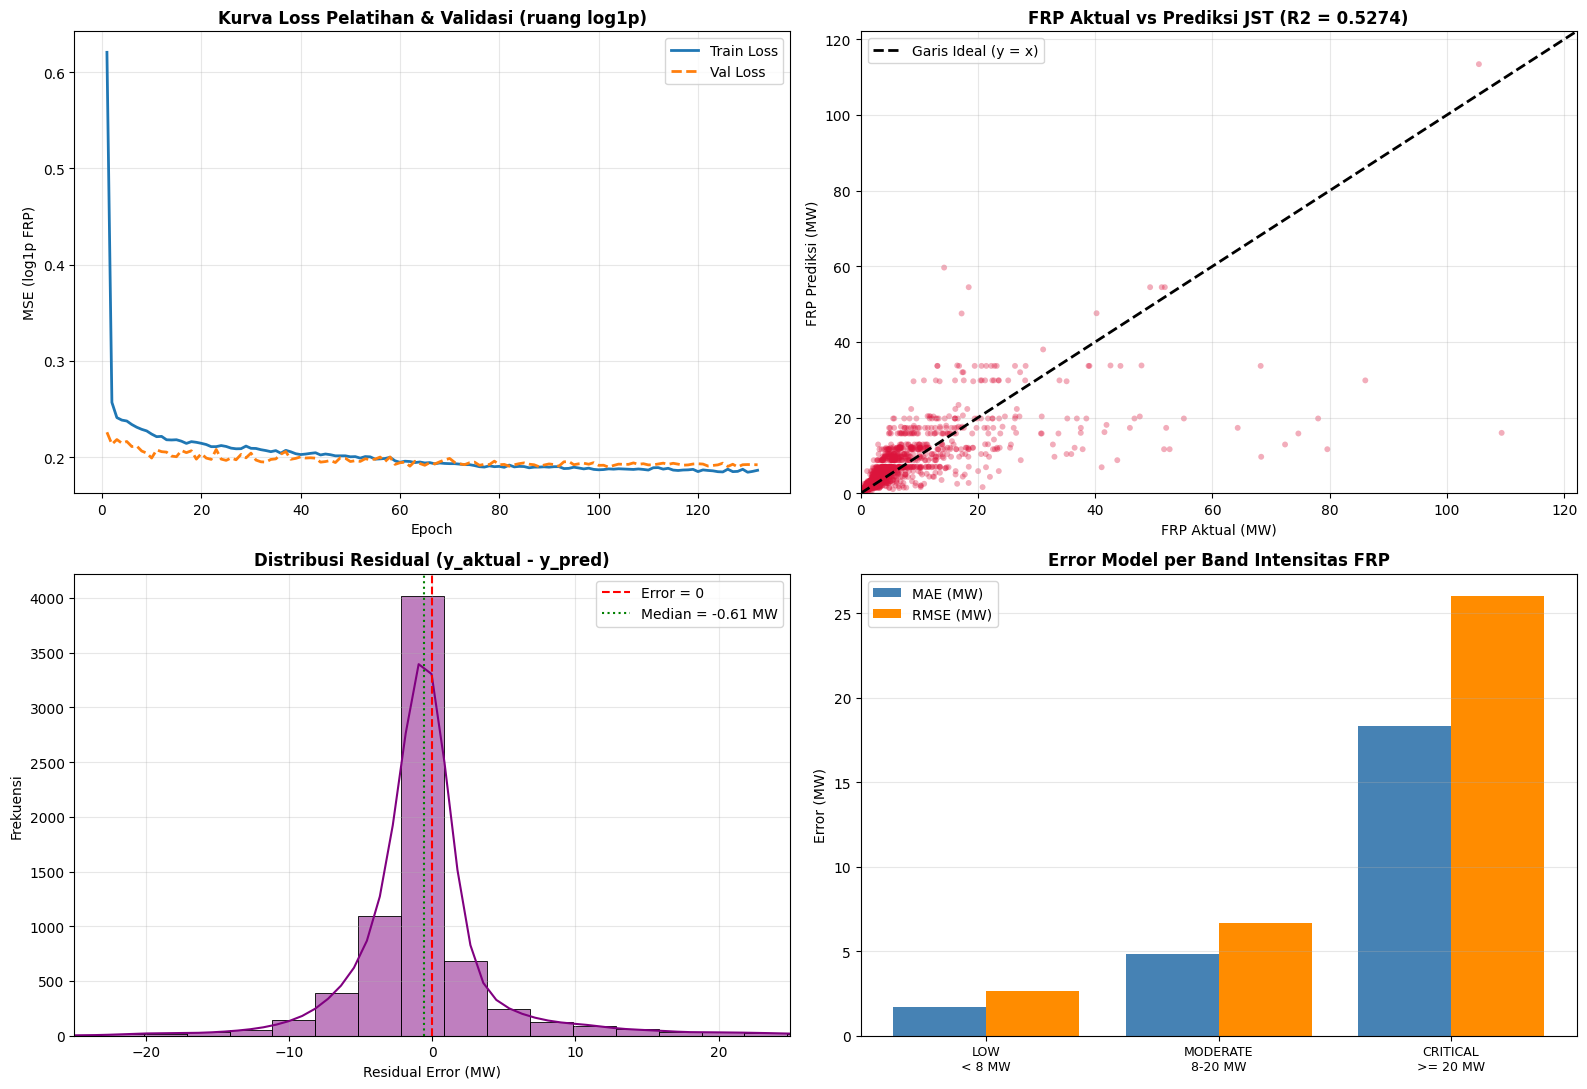

Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
ax.plot(range(1, epochs_run + 1), history['train_loss'], label='Train Loss', color='tab:blue', lw=2)
ax.plot(range(1, epochs_run + 1), history['val_loss'], label='Val Loss', color='tab:orange', lw=2, linestyle='--')
ax.set_title('Kurva Loss Pelatihan & Validasi (ruang log1p)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (log1p FRP)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[0, 1]
subset = np.random.RandomState(SEED).choice(len(y_test), size=min(1500, len(y_test)), replace=False)
ax.scatter(y_test[subset], y_pred_cal[subset], alpha=0.35, color='crimson', edgecolors='none', s=18)
lim = max(np.percentile(y_test[subset], 99.5), np.percentile(y_pred_cal[subset], 99.5)) * 1.05
ax.plot([0, lim], [0, lim], '--k', lw=2, label='Garis Ideal (y = x)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f'FRP Aktual vs Prediksi JST (R2 = {r2:.4f})', fontweight='bold')
ax.set_xlabel('FRP Aktual (MW)'); ax.set_ylabel('FRP Prediksi (MW)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 0]
residuals = y_test - y_pred_cal
sns.histplot(residuals, bins=60, kde=True, color='purple', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Error = 0')
ax.axvline(np.median(residuals), color='green', linestyle=':',
           label=f'Median = {np.median(residuals):.2f} MW')
ax.set_xlim(-25, 25)
ax.set_title('Distribusi Residual (y_aktual - y_pred)', fontweight='bold')
ax.set_xlabel('Residual Error (MW)'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 1]
bands = [('LOW\n< 8 MW', y_test < 8),
         ('MODERATE\n8-20 MW', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL\n>= 20 MW', y_test >= 20)]
x_pos = np.arange(len(bands))
maes = [mean_absolute_error(y_test[m], y_pred_cal[m]) for _, m in bands]
rmses = [np.sqrt(mean_squared_error(y_test[m], y_pred_cal[m])) for _, m in bands]
ax.bar(x_pos - 0.2, maes, 0.4, label='MAE (MW)', color='steelblue')
ax.bar(x_pos + 0.2, rmses, 0.4, label='RMSE (MW)', color='darkorange')
ax.set_xticks(x_pos); ax.set_xticklabels([b for b, _ in bands], fontsize=9)
ax.set_title('Error Model per Band Intensitas FRP', fontweight='bold')
ax.set_ylabel('Error (MW)'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('hasil_evaluasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()
print('Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png')

### 8b. Benchmark XGBoost & Ensemble

Data tabular sering lebih akurat dengan *gradient boosting*. Pipeline identik (fitur, split, dan fitur masukan yang sama) dilatih dengan XGBoost `reg:tweedie` (varians 1,5) — asumsi yang cocok untuk FRP non-negatif dan sangat menceng.

Bobot ensemble dioptimalkan **pada data validasi** (bukan test), sehingga angka uji tetap jujur.

In [12]:
def add_row(rows, name, p):
    m = mean_squared_error(y_test, p)
    rows.append({'Model': name, 'MSE': m, 'RMSE': np.sqrt(m),
                 'MAE': mean_absolute_error(y_test, p), 'R2': r2_score(y_test, p)})

final_rows = [{'Model': 'Baseline (8 fitur, raw MSE)',
               'MSE': BASELINE['MSE'], 'RMSE': BASELINE['RMSE'],
               'MAE': BASELINE['MAE'], 'R2': BASELINE['R2']}]
add_row(final_rows, 'JST + isotonic calibration', y_pred_cal)

# Kandidat model final dinilai pada VALIDASI, bukan test
candidates = {
    'JST + isotonic calibration': (
        mse_of(y_val, y_pred_val_cal),
        lambda Z: np.clip(iso.predict(predict_jst(Z)), 0, None),
        y_pred_cal,
    )
}

try:
    import xgboost as xgb

    X_train_fe, X_val_fe, X_test_fe = X[idx_train], X[idx_val], X[idx_test]
    xgb_model = xgb.XGBRegressor(
        objective='reg:tweedie', tweedie_variance_power=1.5,
        n_estimators=4000, learning_rate=0.03, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0,
        early_stopping_rounds=100, random_state=SEED, tree_method='hist',
        device='cuda' if torch.cuda.is_available() else 'cpu')
    xgb_model.fit(X_train_fe, y_train, eval_set=[(X_val_fe, y_val)], verbose=False)

    y_pred_xgb = np.clip(xgb_model.predict(X_test_fe), 0, None)
    y_pred_xgb_val = np.clip(xgb_model.predict(X_val_fe), 0, None)
    add_row(final_rows, 'XGBoost (tweedie)', y_pred_xgb)

    # Ensemble: bobot dipilih pada validasi
    best_w, best_ens_val = 0.5, float('inf')
    for w in np.arange(0, 1.001, 0.05):
        v = mse_of(y_val, np.clip(w * y_pred_val_cal + (1 - w) * y_pred_xgb_val, 0, None))
        if v < best_ens_val:
            best_ens_val, best_w = v, w

    ens_name = f'Ensemble JST {best_w:.2f} + XGB {1 - best_w:.2f}'
    y_pred_ens = np.clip(best_w * y_pred_cal + (1 - best_w) * y_pred_xgb, 0, None)
    add_row(final_rows, ens_name, y_pred_ens)

    def _ens_predict(Z):
        jst_part = np.clip(iso.predict(predict_jst(Z)), 0, None)
        return np.clip(best_w * jst_part + (1 - best_w) * np.clip(xgb_model.predict(Z), 0, None), 0, None)

    candidates[ens_name] = (best_ens_val, _ens_predict, y_pred_ens)
except ImportError:
    print('xgboost tidak terpasang, benchmark dilewati.')

best_name = min(candidates, key=lambda k: candidates[k][0])
best_val_mse, predict_final, y_pred_final = candidates[best_name]
y_pred_ens = y_pred_final

bench_df = pd.DataFrame(final_rows).sort_values('MSE')
print(f'Model final terpilih (MSE validasi terkecil = {best_val_mse:.4f}): {best_name}')
print('BENCHMARK MODEL (data uji):')
display(bench_df.round(4))

Model final terpilih (MSE validasi terkecil = 72.5186): Ensemble JST 0.35 + XGB 0.65
BENCHMARK MODEL (data uji):


C:\Users\adity\AppData\Roaming\Python\Python314\site-packages\xgboost\core.py:751: UserWarning: [22:28:13] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,Model,MSE,RMSE,MAE,R2
2,XGBoost (tweedie),55.9556,7.4803,3.0824,0.5920
3,Ensemble JST 0.35 + XGB 0.65,56.1572,7.4938,3.1376,0.5906
1,JST + isotonic calibration,64.8233,8.0513,3.4910,0.5274
0,"Baseline (8 fitur, raw MSE)",73.2752,8.5601,3.5324,0.4658


In [13]:
# Evaluasi per-band untuk MODEL FINAL terpilih
bands = [('LOW (< 8 MW)', y_test < 8),
         ('MODERATE (8-20 MW)', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL (>= 20 MW)', y_test >= 20)]

rows = []
for label, mask in bands:
    rows.append({'Band FRP': label, 'n Sampel': int(mask.sum()),
                 'Proporsi': f'{mask.mean() * 100:.1f}%',
                 'MAE (MW)': round(mean_absolute_error(y_test[mask], y_pred_ens[mask]), 3),
                 'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test[mask], y_pred_ens[mask])), 3),
                 'Bias (MW)': round(np.mean(y_pred_ens[mask] - y_test[mask]), 3)})
mse_final = mean_squared_error(y_test, y_pred_ens)
rows.append({'Band FRP': 'SELURUH TEST', 'n Sampel': len(y_test), 'Proporsi': '100.0%',
             'MAE (MW)': round(mean_absolute_error(y_test, y_pred_ens), 3),
             'RMSE (MW)': round(np.sqrt(mse_final), 3),
             'Bias (MW)': round(np.mean(y_pred_ens - y_test), 3)})
band_df = pd.DataFrame(rows)
print(f'PERFORMA MODEL FINAL ({best_name}) PER-BAND:')
display(band_df)

def status(v):
    return np.where(v >= 20, 2, np.where(v >= 8, 1, 0))

acc_status = (status(y_test) == status(y_pred_ens)).mean()
recall_critical = ((status(y_pred_ens) == 2) & (status(y_test) == 2)).sum() / max((status(y_test) == 2).sum(), 1)
print(f'Akurasi status mitigasi (LOW/MODERATE/CRITICAL): {acc_status * 100:.2f}%')
print(f'Recall kelas CRITICAL (>= 20 MW)               : {recall_critical * 100:.2f}%')

PERFORMA MODEL FINAL (Ensemble JST 0.35 + XGB 0.65) PER-BAND:


,Band FRP,n Sampel,Proporsi,MAE (MW),RMSE (MW),Bias (MW)
0,LOW (< 8 MW),5394,75.3%,1.452,2.390,1.001
1,MODERATE (8-20 MW),1224,17.1%,4.498,6.094,0.148
2,CRITICAL (>= 20 MW),548,7.6%,16.691,24.396,-13.634
3,SELURUH TEST,7166,100.0%,3.138,7.494,-0.264


Akurasi status mitigasi (LOW/MODERATE/CRITICAL): 81.61%
Recall kelas CRITICAL (>= 20 MW)               : 49.45%


### 9. Simulasi Inferensi: Estimasi Keganasan Titik Api Baru untuk Mitigasi Lapangan

Titik api baru diperlakukan seperti data satelit terbaru: fitur termal, temporal, dan kerapatan hotspot dibentuk dengan fungsi yang sama seperti saat pelatihan (kerapatan diambil dari tabel historis; sel yang belum tercatat diberi nilai 0). Prediksi memakai **model final terbaik**.

In [14]:
sample_hotspots = pd.DataFrame([
    {'lokasi': 'Katingan (Hutan Gambut Pekat)', 'latitude': -2.05, 'longitude': 113.35, 'bright_ti4': 365.2, 'scan': 0.40, 'track': 0.38, 'bright_ti5': 304.5, 'is_day': 1, 'confidence_score': 3, 'acq_time': 1030, 'day_idx': int(df['day_idx'].max())},
    {'lokasi': 'Seruyan (Dekat Pemukiman)', 'latitude': -2.52, 'longitude': 112.21, 'bright_ti4': 342.1, 'scan': 0.48, 'track': 0.42, 'bright_ti5': 298.0, 'is_day': 1, 'confidence_score': 2, 'acq_time': 1130, 'day_idx': int(df['day_idx'].max())},
    {'lokasi': 'Ketapang (Titik Api Malam Hari)', 'latitude': -1.82, 'longitude': 110.15, 'bright_ti4': 324.6, 'scan': 0.55, 'track': 0.45, 'bright_ti5': 291.3, 'is_day': 0, 'confidence_score': 1, 'acq_time': 130, 'day_idx': int(df['day_idx'].max())}
])

sim_thermal = add_thermal_features(sample_hotspots)
sim_time = add_temporal_features(sim_thermal)
sim_full = pd.concat([sim_time.reset_index(drop=True),
                      add_density_features(sim_time, density_tables).reset_index(drop=True)], axis=1)

X_sim = sim_full[FEATURES].values.astype(np.float32)
pred_frp = predict_final(X_sim)

sample_hotspots['Prediksi FRP (MW)'] = np.round(pred_frp, 2)

def kategori_bahaya(frp_val):
    if frp_val >= 20.0:
        return 'CRITICAL / TINGGI (Prioritaskan Water Bombing Helikopter)'
    elif frp_val >= 8.0:
        return 'MODERATE / SEDANG (Tim Manggala Agni Darat)'
    else:
        return 'LOW / RINGAN (Pemantauan Satelit Berkala)'

sample_hotspots['Status & Rekomendasi Mitigasi'] = sample_hotspots['Prediksi FRP (MW)'].apply(kategori_bahaya)

display(sample_hotspots[['lokasi', 'latitude', 'longitude', 'bright_ti4',
                         'acq_time', 'Prediksi FRP (MW)', 'Status & Rekomendasi Mitigasi']])

,lokasi,latitude,longitude,bright_ti4,acq_time,Prediksi FRP (MW),Status & Rekomendasi Mitigasi
0,Katingan (Hutan Gambut Pekat),-2.05,113.35,365.2,1030,17.03,MODERATE / SEDANG (Tim Manggala Agni Darat)
1,Seruyan (Dekat Pemukiman),-2.52,112.21,342.1,1130,9.92,MODERATE / SEDANG (Tim Manggala Agni Darat)
2,Ketapang (Titik Api Malam Hari),-1.82,110.15,324.6,130,8.25,MODERATE / SEDANG (Tim Manggala Agni Darat)


### 10. Kesimpulan

Perbaikan yang diterapkan dan dampaknya:

1. **Feature engineering (23 fitur)** — fitur temporal (jam akuisisi, indeks hari) dan kerapatan hotspot memberi konteks yang tidak tersedia pada 8 fitur sensor mentah. Fitur kerapatan membantu memisahkan klaster kebakaran besar dari titik api tunggal.
2. **Log-transform target + kalibrasi isotonic** — `log1p` menstabilkan pelatihan pada distribusi yang sangat menceng; kalibrasi isotonic (fit pada validasi) mengoreksi bias `expm1` yang membuat prediksi *underestimate* pada nilai besar — tepat pada segmen yang paling menentukan MSE.
3. **BatchNorm + GELU + AdamW + `ReduceLROnPlateau` + early stopping** — pelatihan lebih stabil dan berhenti pada titik optimal, bukan karena batas epoch.
4. **Evaluasi per-band + analisis konsentrasi error + benchmark XGBoost/ensemble** — mengukur di segmen mana model masih lemah dan menetapkan model final berdasarkan data validasi (bukan test).

**Batasan yang tersisa** (butuh data baru, bukan tuning):
- Tidak ada variabel meteorologi (kelembapan, angin, suhu udara) maupun tutupan lahan/NDVI.
- Periode data hanya 14 hari pada satu musim.
- Tidak ada komponen spasial–temporal eksplisit (deret waktu per sel, tetangga piksel) padahal kebakaran gambut menyebar secara spasial.
- FRP ekstrem (> 50 MW) tetap sulit diprediksi karena populasinya sangat sedikit dan sebagian informasinya tidak terwakili oleh fitur piksel tunggal.